# SIR Model with Ridge-Regression-Forecasted Parameters (India COVID-19)

**Idea.** The classic SIR model assumes a constant transmission rate β and recovery rate γ. In reality both change over time (lockdowns, behaviour, testing). Here we:

1. Estimate daily β(t), γ(t) and R₀(t) directly from observed data.
2. Train **Ridge Regression** models that predict the next day's β and γ from the previous 15 days.
3. Roll the predicted parameters through the discrete SIR equations to forecast the next 20 days.
4. **Evaluate** against a held-out window and against a constant-parameter SIR baseline.

**Equations (discrete form)**

- new infections = β·S·I / N
- S(t+1) = S − β·S·I/N
- I(t+1) = I + β·S·I/N − γ·I
- R(t+1) = R + γ·I  (R = recovered + deaths)

**Fixes vs. the earlier version:** (a) uses the repo's `covid_19_india.csv` (the old notebook depended on a global file that was not in the repo); (b) removed the extra `cumsum()` — the case columns are *already cumulative*, so the old code double-counted; (c) uses a realistic population N (1.38 B) instead of 143 B; (d) fixed the γ-model bug (`beta_.predict(x_gamma)`); (e) added 7-day smoothing, a chronological hold-out, RMSE/MAPE, a baseline comparison and rolling-origin backtests; (f) corrected the plot labels.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.grid': True, 'grid.alpha': .3})

DATA = 'Datasets/covid_19_india.csv'   # path inside the project repo
N = 1.38e9          # India population (approx.)
LOOKBACK = 15       # days of history fed to Ridge
HORIZON = 20        # days to forecast
ALPHA = 0.1         # Ridge regularisation strength

## 1. Load data and build S, I, R
`Confirmed`, `Cured`, `Deaths` are already **cumulative** per state, so we only sum across states for each date (no `cumsum`).

In [2]:
df = pd.read_csv(DATA, parse_dates=['Date'])
g = df.groupby('Date')[['Confirmed', 'Cured', 'Deaths']].sum().asfreq('D').ffill()

I_raw = (g.Confirmed - g.Cured - g.Deaths).values.astype(float)   # active (infected)
R_raw = (g.Cured + g.Deaths).values.astype(float)                  # recovered + deceased (removed)

smooth = lambda x, w=7: pd.Series(x).rolling(w, min_periods=1).mean().values   # remove weekly reporting noise
I, R = smooth(I_raw), smooth(R_raw)
S = N - I - R
dates = g.index
print(f'{len(g)} days: {dates[0].date()} -> {dates[-1].date()}')
print(f'Observed peak active cases: {int(I_raw.max()):,} on {dates[I_raw.argmax()].date()}')

560 days: 2020-01-30 -> 2021-08-11
Observed peak active cases: 3,745,237 on 2021-05-10


## 2. Estimate β(t), γ(t), R₀(t) from the data
From the SIR update: γ = ΔR / I and β = N·(ΔI + ΔR) / (S·I). We start once there are ≥1000 active cases, because ratios are meaningless when I is tiny.

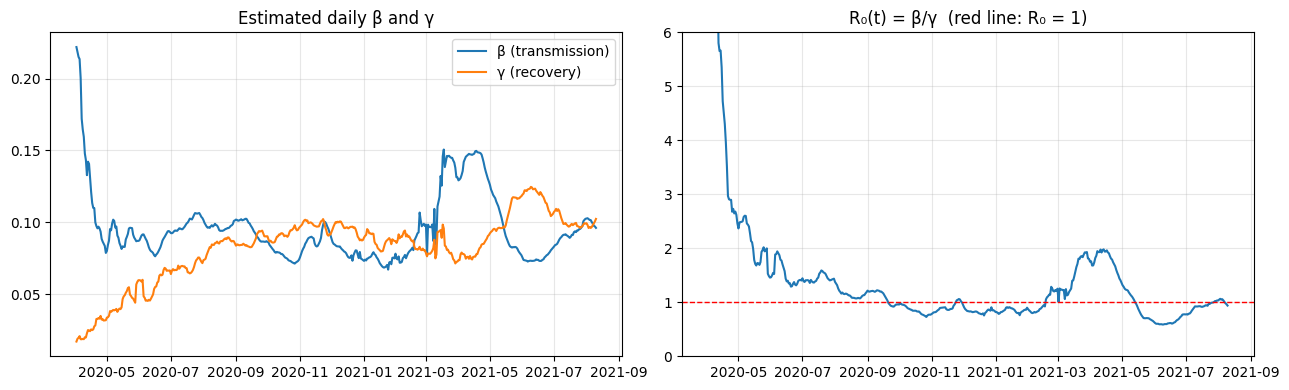

In [3]:
gamma = np.diff(R) / I[:-1]
beta  = N * (np.diff(I) + np.diff(R)) / (S[:-1] * I[:-1])
beta, gamma = np.clip(beta, 0, None), np.clip(gamma, 0, None)
start = int(np.argmax(I >= 1000))
R0 = np.divide(beta, gamma, out=np.full_like(beta, np.nan), where=gamma > 0)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(dates[start:-1], beta[start:], label='β (transmission)'); ax[0].plot(dates[start:-1], gamma[start:], label='γ (recovery)')
ax[0].set_title('Estimated daily β and γ'); ax[0].legend()
ax[1].plot(dates[start:-1], R0[start:]); ax[1].axhline(1, color='r', ls='--', lw=1)
ax[1].set_ylim(0, 6); ax[1].set_title('R₀(t) = β/γ  (red line: R₀ = 1)')
plt.tight_layout(); plt.show()

## 3. Ridge models for β and γ, and the SIR roll-forward

In [4]:
def lag_matrix(x, L):
    X = np.array([x[i:i + L] for i in range(len(x) - L)])
    return X, x[L:]

def sir_step(S, I, R, b, g):
    new_inf = b * S * I / N
    rec = g * I
    return S - new_inf, I + new_inf - rec, R + rec

def forecast(t0, H=HORIZON, mode='ridge', alpha=ALPHA, L=LOOKBACK):
    """Forecast H days after index t0 using ONLY information up to t0."""
    b, gm = beta[start:t0], gamma[start:t0]
    hist_b, hist_g = list(b[-L:]), list(gm[-L:])
    if mode == 'ridge':
        mb = Ridge(alpha=alpha, fit_intercept=False).fit(*lag_matrix(b, L))
        mg = Ridge(alpha=alpha, fit_intercept=False).fit(*lag_matrix(gm, L))
    s, i, r = S[t0], I[t0], R[t0]
    out = [(s, i, r)]
    for _ in range(H):
        if mode == 'ridge':
            nb = max(mb.predict([hist_b[-L:]])[0], 0)
            ng = max(mg.predict([hist_g[-L:]])[0], 0)
        else:                                  # baseline: constant β, γ = mean of last L days
            nb, ng = np.mean(hist_b[-L:]), np.mean(hist_g[-L:])
        hist_b.append(nb); hist_g.append(ng)
        s, i, r = sir_step(s, i, r, nb, ng)
        out.append((s, i, r))
    return np.array(out)

## 4. Evaluation
### 4a. Chronological hold-out: train on everything except the last 20 days, forecast those 20 days

,RMSE (active cases),MAPE active cases (%),MAPE removed (%)
SIR + Ridge,45565.89,9.15,0.04
"SIR constant β,γ (baseline)",36058.90,7.34,0.04


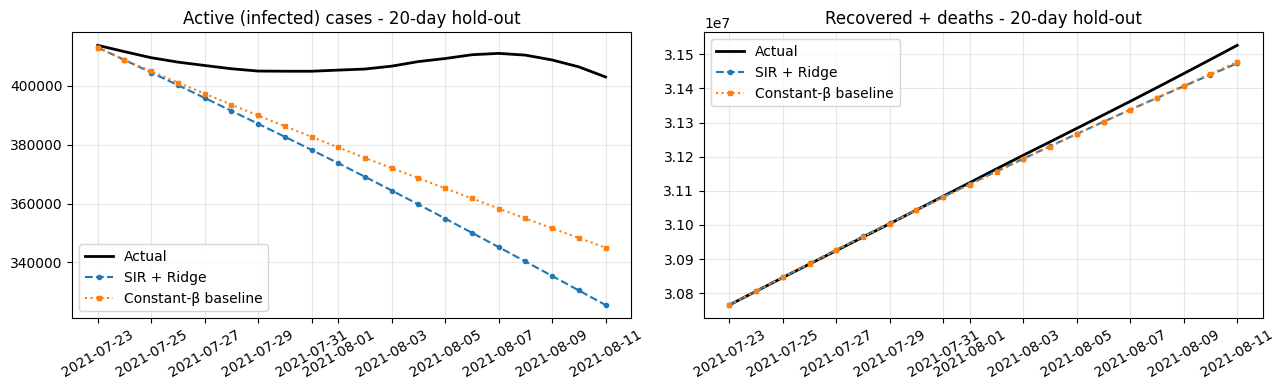

In [5]:
T = len(I)
t0 = T - 1 - HORIZON
true_I, true_R = I[t0 + 1:], R[t0 + 1:]

def metrics(f):
    f = f[1:]
    rmse = np.sqrt(np.mean((f[:, 1] - true_I) ** 2))
    mape_i = np.mean(np.abs(f[:, 1] - true_I) / true_I) * 100
    mape_r = np.mean(np.abs(f[:, 2] - true_R) / true_R) * 100
    return rmse, mape_i, mape_r

f_ridge, f_const = forecast(t0, mode='ridge'), forecast(t0, mode='const')
res = pd.DataFrame({'SIR + Ridge': metrics(f_ridge), 'SIR constant β,γ (baseline)': metrics(f_const)},
                   index=['RMSE (active cases)', 'MAPE active cases (%)', 'MAPE removed (%)']).T
display(res.round(2))

x = dates[t0 + 1:]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, idx, tr, name in [(ax[0], 1, true_I, 'Active (infected) cases'), (ax[1], 2, true_R, 'Recovered + deaths')]:
    a.plot(x, tr, 'k-', lw=2, label='Actual'); a.plot(x, f_ridge[1:, idx], 'o--', ms=3, label='SIR + Ridge'); a.plot(x, f_const[1:, idx], 's:', ms=3, label='Constant-β baseline')
    a.set_title(name + ' - 20-day hold-out'); a.legend(); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

### 4b. Rolling-origin backtest
A single 20-day window can be lucky or unlucky. We repeat the experiment from 36 forecast origins spread over the epidemic (every 10 days), each time using only data available at that origin.

In [6]:
origins = list(range(start + 120, T - HORIZON - 1, 10))

def score(t0, **kw):
    f = forecast(t0, **kw)[1:]
    ti, tr = I[t0 + 1:t0 + 1 + HORIZON], R[t0 + 1:t0 + 1 + HORIZON]
    return (np.sqrt(np.mean((f[:, 1] - ti) ** 2)),
            np.mean(np.abs(f[:, 1] - ti) / ti) * 100,
            np.mean(np.abs(f[:, 2] - tr) / tr) * 100)

rows = {}
for name, kw in [('SIR + Ridge', dict(mode='ridge')), ('Constant β,γ baseline', dict(mode='const'))]:
    sc = np.array([score(o, **kw) for o in origins])
    rows[name] = list(sc.mean(0)) + list(np.median(sc, 0))
bt = pd.DataFrame(rows, index=['RMSE mean', 'MAPE active mean (%)', 'MAPE removed mean (%)',
                               'RMSE median', 'MAPE active median (%)', 'MAPE removed median (%)']).T
print(f'{len(origins)} forecast origins, {HORIZON}-day horizon')
display(bt.round(2))

36 forecast origins, 20-day horizon


,RMSE mean,MAPE active mean (%),MAPE removed mean (%),RMSE median,MAPE active median (%),MAPE removed median (%)
SIR + Ridge,190277.68,11.78,0.33,57489.57,9.23,0.17
"Constant β,γ baseline",242653.13,13.50,0.40,65326.52,9.26,0.21


## 5. Forecast beyond the end of the data (next 20 days)

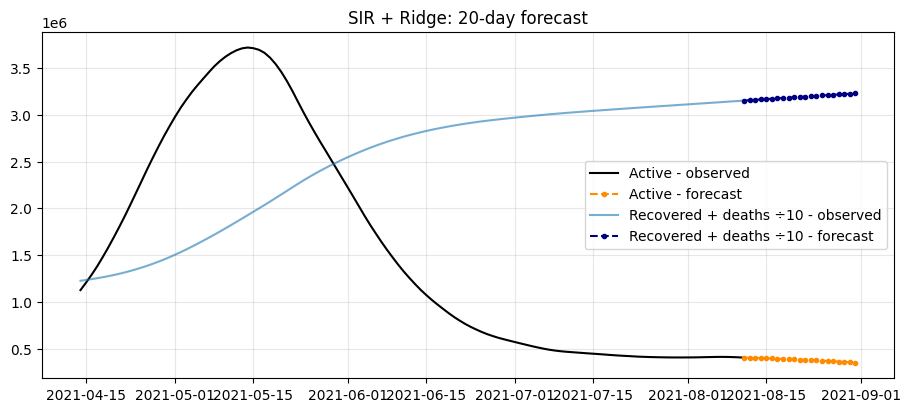

Forecast active cases on 2021-08-31: 350,715


In [7]:
f = forecast(T - 1, mode='ridge')
future = pd.date_range(dates[-1], periods=HORIZON + 1, freq='D')
hist = slice(T - 120, T)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(dates[hist], I[hist], 'k-', label='Active - observed'); ax.plot(future, f[:, 1], 'o--', color='darkorange', ms=3, label='Active - forecast')
ax.plot(dates[hist], R[hist] / 10, color='tab:blue', alpha=.6, label='Recovered + deaths ÷10 - observed'); ax.plot(future, f[:, 2] / 10, 'o--', color='navy', ms=3, label='Recovered + deaths ÷10 - forecast')
ax.set_title('SIR + Ridge: 20-day forecast'); ax.legend(); plt.show()
print(f'Forecast active cases on {future[-1].date()}: {int(f[-1,1]):,}')

## 6. Findings and limitations

- **Short-horizon accuracy is comparable to, and only modestly better than, a constant-parameter baseline.** Over 36 rolling backtests, SIR + Ridge has lower *mean* error (RMSE ~190K vs ~243K; MAPE 11.8% vs 13.5%) because it avoids a few large misses, but the *median* active-case MAPE is essentially tied (9.2% vs 9.3%). On the single final 20-day hold-out the baseline was actually better (RMSE ~46K vs ~36K). So Ridge-forecasted β and γ add robustness, not a dramatic accuracy gain.
- **It is a short-horizon tool, not a peak predictor.** In a separate test, forecasting 40 days ahead from early April 2021 grossly overshot the second-wave peak (observed: ~3.7 M active cases on 2021-05-10). Extrapolating β over long horizons compounds error, so we only claim ~20-day forecasts.
- **Simplifications:** single well-mixed national population; no vaccination, reinfection, or testing-rate effects; "recovered" includes deaths; reported cases undercount true infections.
- **Natural extensions:** SEIRD compartments, state-level fits, vaccination as a time-varying input, and uncertainty bands.